In [1]:
!pip install -q rdkit pandas scikit-learn openpyxl pytdc


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... canceled
ERROR: Operation cancelled by user


In [ ]:
import pandas as pd
activities   = pd.read_excel('chembl_herg_activities.xlsx')
assays = pd.read_excel('chembl_herg_assays.xlsx')
print(activities.shape, assays.shape)
activities.head()

(19840, 47) (4829, 29)


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,NaN,NaN,224312,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,1200.0
1,NaN,NaN,225577,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,730.0
2,NaN,NaN,228175,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,43.0
3,NaN,NaN,232020,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,1200.0
4,NaN,NaN,232022,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,460.0


keeping only whats needed

In [ ]:
df = activities[activities.pchembl_value.notna() & activities.canonical_smiles.notna()].copy()
print(len(df))

13519


In [ ]:
df.head()

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,NaN,NaN,224312,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,1200.0
1,NaN,NaN,225577,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,730.0
2,NaN,NaN,228175,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,43.0
3,NaN,NaN,232020,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,1200.0
4,NaN,NaN,232022,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Homo sapiens,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,460.0


In [ ]:
from rdkit import Chem
print(dir(Chem))


['ADJUST_IGNOREALL', 'ADJUST_IGNORECHAINS', 'ADJUST_IGNOREDUMMIES', 'ADJUST_IGNOREMAPPED', 'ADJUST_IGNORENONDUMMIES', 'ADJUST_IGNORENONE', 'ADJUST_IGNORERINGS', 'ALLOW_CHARGE_SEPARATION', 'ALLOW_INCOMPLETE_OCTETS', 'AROMATICITY_CUSTOM', 'AROMATICITY_DEFAULT', 'AROMATICITY_MDL', 'AROMATICITY_MMFF94', 'AROMATICITY_RDKIT', 'AROMATICITY_SIMPLE', 'ATTACHMENT_POINT_LABEL_PREFIX', 'AddHs', 'AddHsParameters', 'AddMetadataToPNGFile', 'AddMetadataToPNGString', 'AddMolSubstanceGroup', 'AddRecursiveQuery', 'AddStereoAnnotations', 'AddWavyBondsForStereoAny', 'AdjustQueryParameters', 'AdjustQueryProperties', 'AdjustQueryPropertiesWithGenericGroups', 'AdjustQueryWhichFlags', 'AllProps', 'AromaticityModel', 'AssignAtomChiralTagsFromMolParity', 'AssignAtomChiralTagsFromStructure', 'AssignCIPLabels', 'AssignChiralTypesFromBondDirs', 'AssignRadicals', 'AssignStereochemistry', 'AssignStereochemistryFrom3D', 'Atom', 'AtomCoordsMatcher', 'AtomFromSmarts', 'AtomFromSmiles', 'AtomHasConjugatedBond', 'AtomKeku

In [ ]:
from rdkit import Chem
Chem

<module 'rdkit.Chem' from '/usr/local/lib/python3.13/dist-packages/rdkit/Chem/__init__.py'>

In [ ]:
from rdkit.Chem.MolStandardize import rdMolStandardize
print(dir(rdMolStandardize))

['AllowedAtomsValidation', 'CHARGE_CORRECTIONS', 'CanonicalTautomer', 'ChargeCorrection', 'ChargeParent', 'ChargeParentInPlace', 'Cleanup', 'CleanupInPlace', 'CleanupParameters', 'DisallowedAtomsValidation', 'DisallowedRadicalValidation', 'DisconnectOrganometallics', 'DisconnectOrganometallicsInPlace', 'FeaturesValidation', 'FragmentParent', 'FragmentParentInPlace', 'FragmentRemover', 'FragmentRemoverFromData', 'FragmentValidation', 'GetDefaultTautomerScoreSubstructs', 'GetV1TautomerEnumerator', 'Is2DValidation', 'IsotopeParent', 'IsotopeParentInPlace', 'IsotopeValidation', 'LargestFragmentChooser', 'Layout2DValidation', 'MetalDisconnector', 'MetalDisconnectorOptions', 'MolVSValidation', 'NeutralValidation', 'NoAtomValidation', 'Normalize', 'NormalizeInPlace', 'Normalizer', 'NormalizerFromData', 'NormalizerFromParams', 'Pipeline', 'PipelineLog', 'PipelineLogEntry', 'PipelineOptions', 'PipelineResult', 'PipelineStage', 'PipelineStatus', 'RDKitValidation', 'Reionize', 'ReionizeInPlace', 

https://www.rdkit.org/docs/source/rdkit.Chem.MolStandardize.rdMolStandardize.html
this is the link for rdmolstandardize , this command chooses the largest fragment and removes the salts, keeps the fragment without it, it neutralises the charges, and MolToSmiles writes the molecule back as canonical SMILES, so the same molecule always gets the same string.


rdlogger just gives a log of everything, thats disables to keep the notebook clean

In [ ]:
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

chooser  = rdMolStandardize.LargestFragmentChooser()
uncharge = rdMolStandardize.Uncharger()

def clean(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    m = chooser.choose(m)
    m = uncharge.uncharge(m)
    return Chem.MolToSmiles(m)

df['smiles'] = df.canonical_smiles.map(clean)
df = df[df.smiles.notna()]
print(len(df))

13519


In [ ]:
df.head()

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value,smiles
0,NaN,NaN,224312,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,1200.0,CC(C(=O)N[C@]1(c2ccccc2)CC[C@@H](N2CCN(C(C)C)C...
1,NaN,NaN,225577,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,730.0,CC(C(=O)NC1(c2ccccc2)CCC(N2CCC3(CCCO3)CC2)CC1)...
2,NaN,NaN,228175,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,43.0,CC(C(=O)N[C@]1(c2ccccc2)CC[C@@H](N2CCC(c3ccc(F...
3,NaN,NaN,232020,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,1200.0,CC(C(=O)N[C@]1(c2ccccc2)CC[C@H](N2CCCCC2)CC1)c...
4,NaN,NaN,232022,[],CHEMBL824627,Compound was evaluated for the displacement of...,B,NaN,NaN,BAO_0000192,...,Voltage-gated inwardly rectifying potassium ch...,9606,NaN,NaN,Ki,nM,UO_0000065,NaN,460.0,CC1CCN([C@H]2CC[C@](NC(=O)C(C)c3cc(C(F)(F)F)cc...


removing duplicates

In [ ]:
mol = df.groupby('smiles').pchembl_value.agg(pchembl='median', n='count').reset_index()
print(len(mol))
mol.head()

10884


,smiles,pchembl,n
0,Brc1cc(Br)cc([C@H]2C[C@@H](CN3CCCC3)N2Cc2ccccc...,4.60,1
1,Brc1ccc(Nc2ccc(CN3CCC4(CC3)OCCc3sccc34)cc2)cc1,5.37,2
2,Brc1ccc2c(NC3=NC[C@@]4(CN5CCC4CC5)O3)ncnn12,5.60,1
3,Brc1cccc2nc(C#Cc3ccccn3)ccc12,4.64,1
4,Brc1cnc2nc(N3CCN4CCC3CC4)oc2c1,5.64,1


In [ ]:
import numpy as np
from rdkit.Chem import rdFingerprintGenerator
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def fingerprint(smi):
    return gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(smi))

X = np.vstack(mol.smiles.map(fingerprint).values).astype(np.uint8)
y = mol.pchembl.values

print(X.shape, y.shape)
print(y[:5])


(10884, 2048) (10884,)
[4.6  5.37 5.6  4.64 5.64]


In [ ]:
from collections import defaultdict
from rdkit.Chem.Scaffolds import MurckoScaffold

In [ ]:
def scaffold_split(smiles, test_frac=0.2, seed=42):
      groups = defaultdict(list)
      for i, s in enumerate(smiles):
        groups[MurckoScaffold.MurckoScaffoldSmiles(smiles=s)].append(i)

In [ ]:
from collections import defaultdict
from rdkit.Chem.Scaffolds import MurckoScaffold

def scaffold_split(smiles, test_frac=0.2, seed=42):
    groups = defaultdict(list)
    for i, s in enumerate(smiles):
        groups[MurckoScaffold.MurckoScaffoldSmiles(smiles=s)].append(i)
    sets = list(groups.values())
    rng = np.random.RandomState(seed); rng.shuffle(sets)
    sets.sort(key=len, reverse=True)
    n_test = int(test_frac * len(smiles))
    train, test = [], []
    for g in sets:
        (train if len(train) + len(g) <= len(smiles) - n_test else test).extend(g)
    return np.array(train), np.array(test)

tr, te = scaffold_split(mol.smiles.tolist())

train / test: 8708 2176
scaffolds in BOTH sets (must be 0): 0
pChEMBL mean, sd  train: 5.48 0.9 | test: 5.45 0.86
median nearest-train similarity: 0.68


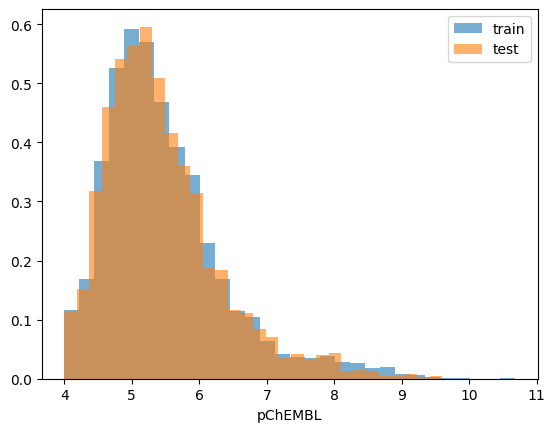

In [ ]:
import matplotlib.pyplot as plt

scaf = mol.smiles.map(lambda s: MurckoScaffold.MurckoScaffoldSmiles(smiles=s))
print('train / test:', len(tr), len(te))
print('scaffolds in BOTH sets (must be 0):', len(set(scaf.iloc[tr]) & set(scaf.iloc[te])))
print('pChEMBL mean, sd  train:', y[tr].mean().round(2), y[tr].std().round(2),
      '| test:', y[te].mean().round(2), y[te].std().round(2))

# how "new" is each test molecule? similarity to its closest training molecule
Xf = X.astype(np.float32); n = Xf.sum(axis=1)
def nearest_sim(a, b):
    inter = Xf[a] @ Xf[b].T
    return (inter / (n[a][:, None] + n[b][None, :] - inter)).max(axis=1)
print('median nearest-train similarity:', np.median(nearest_sim(te, tr)).round(2))

plt.hist(y[tr], bins=30, density=True, alpha=.6, label='train')
plt.hist(y[te], bins=30, density=True, alpha=.6, label='test')
plt.xlabel('pChEMBL'); plt.legend(); plt.show()

variance explained: 0.046


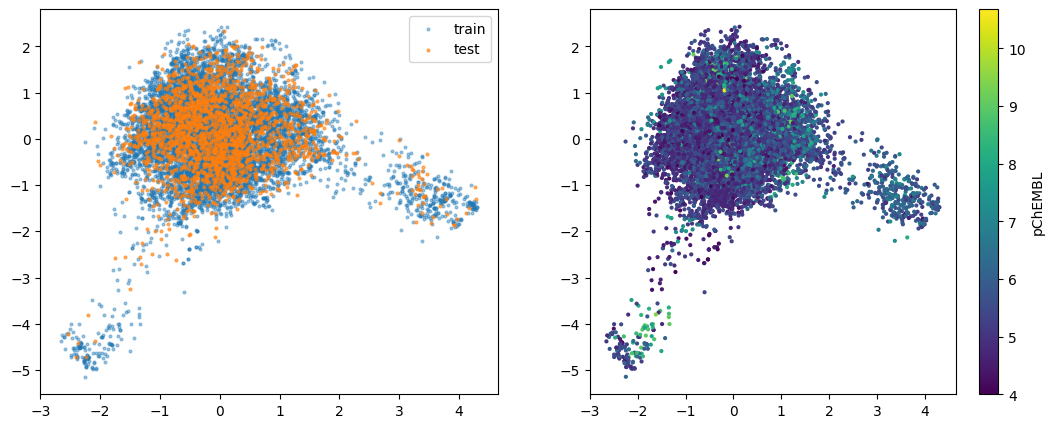

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(X[tr])   # learn the axes from train only
Z = pca.transform(X)
print('variance explained:', pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(Z[tr,0], Z[tr,1], s=4, alpha=.4, label='train')
ax[0].scatter(Z[te,0], Z[te,1], s=4, alpha=.6, label='test'); ax[0].legend()
sc = ax[1].scatter(Z[:,0], Z[:,1], c=y, s=4, cmap='viridis')
plt.colorbar(sc, ax=ax[1], label='pChEMBL'); plt.show()

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

Xb = X.astype(bool)
models = {
    'Baseline (mean)':    DummyRegressor(),
    'Ridge':              Ridge(alpha=10),
    'kNN (k=5, Jaccard)': KNeighborsRegressor(n_neighbors=5, metric='jaccard', algorithm='brute', n_jobs=-1),
    'SVR (RBF)':          SVR(C=5),
    'Random Forest':      RandomForestRegressor(n_estimators=300, max_features='sqrt', n_jobs=-1, random_state=42),
}
rows, preds = [], {}
for name, m in models.items():
    m.fit(Xb[tr], y[tr])
    p = m.predict(Xb[te]); preds[name] = p
    rows.append({'model': name, 'R2': r2_score(y[te], p),
                 'RMSE': np.sqrt(mean_squared_error(y[te], p)),
                 'MAE': mean_absolute_error(y[te], p),
                 'Spearman': spearmanr(y[te], p)[0]})
results = pd.DataFrame(rows).sort_values('RMSE').round(3)
results

/tmp/ipykernel_2308/35050389.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'Spearman': spearmanr(y[te], p)[0]})


,model,R2,RMSE,MAE,Spearman
3,SVR (RBF),0.464,0.633,0.474,0.604
4,Random Forest,0.438,0.648,0.488,0.581
2,"kNN (k=5, Jaccard)",0.330,0.707,0.523,0.520
1,Ridge,0.257,0.745,0.572,0.483
0,Baseline (mean),-0.001,0.865,0.658,NaN


23464 similar pairs | 638 cliff pairs


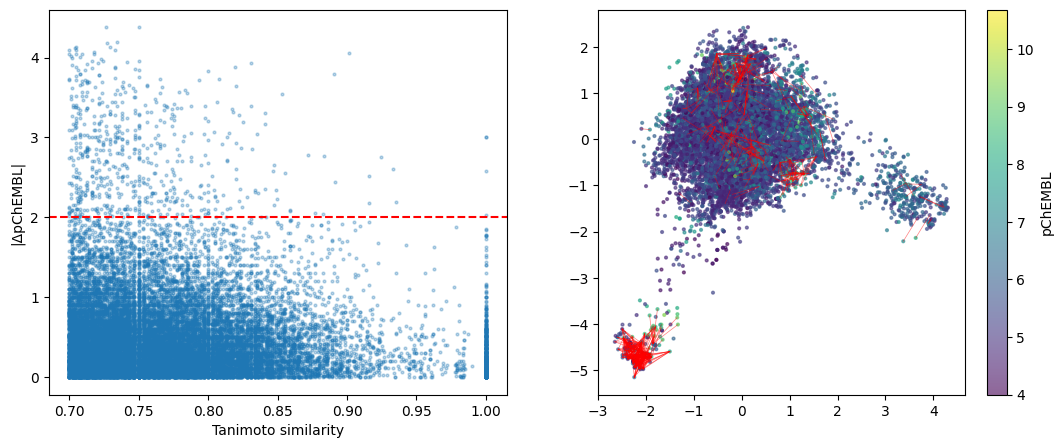

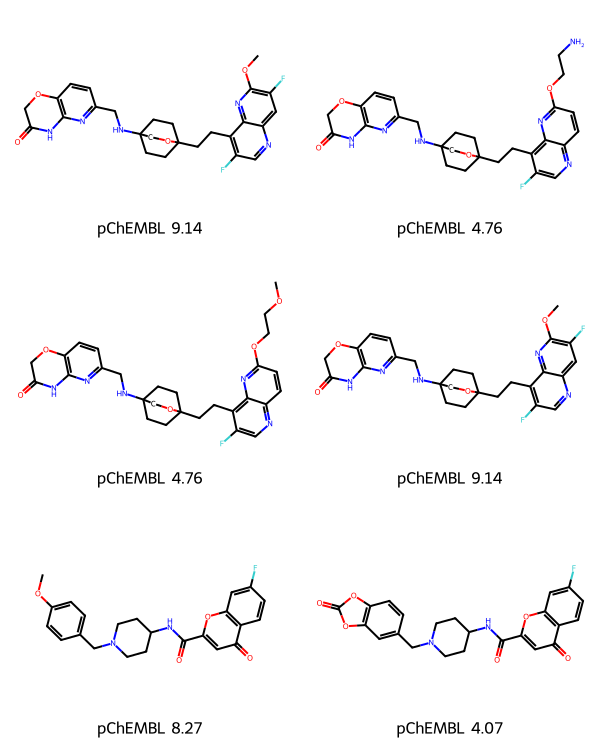

In [ ]:
from rdkit.Chem import Draw

SIM_CUT, DELTA_CUT = 0.7, 2.0
I, J, S = [], [], []
for start in range(0, len(Xf), 1000):                    # chunks keep memory small
    inter = Xf[start:start+1000] @ Xf.T
    sim = inter / (n[start:start+1000, None] + n[None, :] - inter)
    ii, jj = np.where(sim >= SIM_CUT)
    keep = (ii + start) < jj                              # each pair once
    I.append(ii[keep] + start); J.append(jj[keep]); S.append(sim[ii[keep], jj[keep]])
pairs = pd.DataFrame({'i': np.concatenate(I), 'j': np.concatenate(J), 'sim': np.concatenate(S)})
pairs['delta'] = np.abs(y[pairs.i.values] - y[pairs.j.values])
cliffs = pairs[pairs.delta >= DELTA_CUT].sort_values('delta', ascending=False)
print(len(pairs), 'similar pairs |', len(cliffs), 'cliff pairs')

# second PCA, with cliff pairs joined by red lines
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(pairs.sim, pairs.delta, s=4, alpha=.3); ax[0].axhline(DELTA_CUT, color='r', ls='--')
ax[0].set_xlabel('Tanimoto similarity'); ax[0].set_ylabel('|ΔpChEMBL|')
sc = ax[1].scatter(Z[:,0], Z[:,1], c=y, s=4, alpha=.6)
for _, r in cliffs.iterrows():
    ax[1].plot(Z[[int(r.i), int(r.j)], 0], Z[[int(r.i), int(r.j)], 1], color='red', lw=.5, alpha=.5)
plt.colorbar(sc, ax=ax[1], label='pChEMBL'); plt.show()

# look at the 3 biggest cliffs as structures
mols, legends = [], []
for _, r in cliffs.head(3).iterrows():
    for k in (int(r.i), int(r.j)):
        mols.append(Chem.MolFromSmiles(mol.smiles[k])); legends.append(f'pChEMBL {y[k]:.2f}')
Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(300, 250), legends=legends)

In [ ]:
# 1) do models do worse on cliff molecules?
cliff_mols = set(cliffs.i) | set(cliffs.j)
in_cliff = np.array([i in cliff_mols for i in te])
for name in ['Random Forest', 'SVR (RBF)']:
    err = np.abs(preds[name] - y[te])
    print(name, '| MAE on cliff molecules:', err[in_cliff].mean().round(2), '| others:', err[~in_cliff].mean().round(2))

# 2) do the two molecules of a pair come from different papers?
doc = df.groupby('smiles').document_chembl_id.agg(set)
def different_papers(p):
    return np.mean([doc[mol.smiles[int(a)]].isdisjoint(doc[mol.smiles[int(b)]]) for a, b in zip(p.i, p.j)])
print('cliff pairs, no shared paper:', different_papers(cliffs).round(2))
print('all similar pairs, no shared paper:', different_papers(pairs).round(2))

Random Forest | MAE on cliff molecules: 1.19 | others: 0.47
SVR (RBF) | MAE on cliff molecules: 1.08 | others: 0.46
cliff pairs, no shared paper: 0.57
all similar pairs, no shared paper: 0.08
